# Conclusão geral

## Objetivo e hipótese

Este estudo investigou se é possível identificar pessoas com depressão usando informações do NHIS 2025 sem fornecer aos modelos os próprios sintomas de depressão ou de ansiedade. A pergunta é relevante porque, em um cenário de rastreio, pode ser útil reconhecer sinais associados à depressão mesmo quando não há respostas diretas a questionários de saúde mental.

Foram comparados dois cenários: **A**, exploratório, que mantém as variáveis de ansiedade; e **B**, principal para a hipótese, que remove os sintomas e demais variáveis de depressão (PHQ) e ansiedade (GAD-7). O cenário A serve como referência de desempenho quando há informação de ansiedade, que costuma estar associada à depressão. A hipótese central é avaliada pelo cenário B.

## Como a comparação foi conduzida

- Os quatro algoritmos — Random Forest, KNN, SVM e XGBoost — foram avaliados com os mesmos 22.084 registros completos e o mesmo split estratificado de treino e teste (80/20, `random_state=42`), para tornar os resultados comparáveis.
- O desfecho foi tratado como classificação binária: registros sem depressão versus registros com depressão. Respostas inválidas ou indefinidas no alvo foram excluídas.
- O peso amostral serve apenas para extrapolar os resultados da amostra para a população dos Estados Unidos; ele não foi usado para treinar os modelos. As matrizes de confusão mostram o número de pessoas da amostra de teste.
- A escolha de hiperparâmetros e dos limiares de recall foi feita sem usar o conjunto de teste. Os limiares para recall-alvo foram escolhidos no treino, com validação cruzada; portanto, o recall efetivamente obtido no teste pode não ser exatamente o alvo.




## Matrizes de confusão dos algoritmos

Comparação dos modelos ajustados do **cenário B**, nos mesmos registros de teste. O primeiro gráfico usa o limiar padrão de cada modelo; o segundo, na célula seguinte, usa o limiar selecionado no treino para recall-alvo de 90%. As duas figuras usam a mesma escala de cores.

Cada setor mostra o **número de pessoas** e a **porcentagem em relação à classe real** (cada linha soma 100%): VN = verdadeiro negativo, FP = falso positivo, FN = falso negativo e VP = verdadeiro positivo. Assim, a porcentagem em VP é o recall.

A célula abaixo lê as contagens inteiras das tabelas de limiares já salvas nos quatro notebooks, sem retreinar os modelos. Se eles forem atualizados, execute e salve novamente suas tabelas de limiares antes de atualizar este gráfico.

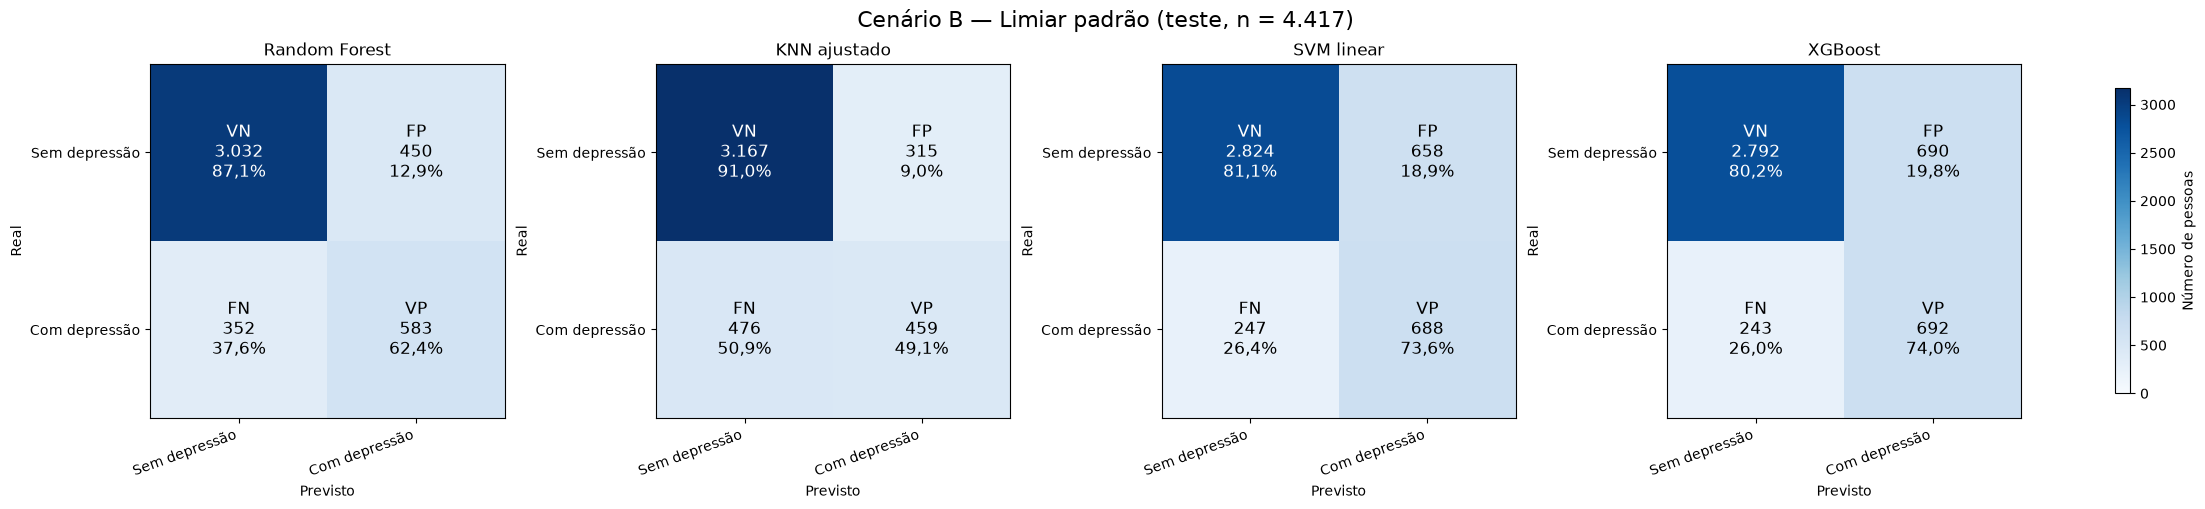

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

pasta_modelos = next((p for p in (Path('.'), Path('03 Modelos supervisionados'))
                      if (p / 'SVM' / '08_00_svm_classificacao_2025.ipynb').is_file()), None)
if pasta_modelos is None:
    raise FileNotFoundError('Execute a partir da pasta de modelos supervisionados ou da raiz do projeto.')

MODELOS = {
    'Random Forest': ('Random Forest/06_random_forest_depressao_2025.ipynb', 'tabela_lim_b'),
    'KNN ajustado': ('KNN/08_00_knn_classificacao_2025.ipynb', 'tabela_lim_b'),
    'SVM linear': ('SVM/08_00_svm_classificacao_2025.ipynb', 'tabela_lim_b'),
    'XGBoost': ('XGBoost/07_00_xgboost_classificacao_2025.ipynb', 'tabela_lim_b'),
}


def ler_contagens(arquivo, nome_tabela):
    with arquivo.open(encoding='utf-8') as f:
        notebook = json.load(f)
    for celula in notebook['cells']:
        fonte = ''.join(celula.get('source', []))
        if not fonte.startswith(f'{nome_tabela},') and f'\n{nome_tabela},' not in fonte:
            continue
        for saida in celula.get('outputs', []):
            tabela = saida.get('data', {}).get('application/vnd.microsoft.datawrangler.viewer.v0+json')
            if tabela is None:
                continue
            colunas = [c['name'] for c in tabela['columns']]
            if not {'index', 'TN', 'FP', 'FN', 'TP'} <= set(colunas):
                continue
            registros = [dict(zip(colunas, linha)) for linha in tabela['rows']]
            selecionados = {
                'Limiar padrão': [r for r in registros if r['index'].startswith('Padrão')],
                'Recall-alvo 90%': [r for r in registros if r['index'] == 'Recall-alvo 90%'],
            }
            if any(len(linhas) != 1 for linhas in selecionados.values()):
                raise ValueError(f'Linhas de limiares ausentes ou duplicadas em {arquivo}: {nome_tabela}')
            matrizes = {}
            for ponto, linhas in selecionados.items():
                r = linhas[0]
                matriz = np.array([[int(r['TN']), int(r['FP'])], [int(r['FN']), int(r['TP'])]])
                if (matriz < 0).any() or (matriz.sum(axis=1) == 0).any():
                    raise ValueError(f'Contagens inválidas em {arquivo}: {nome_tabela}, {ponto}')
                matrizes[ponto] = matriz
            return matrizes
    raise ValueError(f'Tabela {nome_tabela} não encontrada em {arquivo}. Execute e salve sua célula de limiares.')


matrizes_modelos = {nome: ler_contagens(pasta_modelos / arquivo, tabela)
                    for nome, (arquivo, tabela) in MODELOS.items()}
totais_reais = next(iter(matrizes_modelos.values()))['Limiar padrão'].sum(axis=1)
if any(not np.array_equal(m.sum(axis=1), totais_reais)
       for pontos in matrizes_modelos.values() for m in pontos.values()):
    raise ValueError('As matrizes não têm os mesmos totais por classe real. Confira os conjuntos de teste.')

ESCALA_CORES = Normalize(vmin=0, vmax=max(m.max() for pontos in matrizes_modelos.values() for m in pontos.values()))
pasta_imagens = pasta_modelos.resolve().parent / 'repositorio imagens' / '03 Modelos supervisionados'
pasta_imagens.mkdir(parents=True, exist_ok=True)


def plotar_matrizes(ponto, nome_arquivo):
    fig, eixos = plt.subplots(1, len(MODELOS), figsize=(22, 5), layout='constrained')
    for eixo, (nome, pontos) in zip(eixos, matrizes_modelos.items()):
        matriz = pontos[ponto]
        imagem = eixo.imshow(matriz, cmap='Blues', norm=ESCALA_CORES)
        percentuais = matriz / matriz.sum(axis=1, keepdims=True)
        for (i, j), valor in np.ndenumerate(matriz):
            sigla = [['VN', 'FP'], ['FN', 'VP']][i][j]
            texto = f'{sigla}\n{valor:,}'.replace(',', '.') + f'\n{percentuais[i, j]:.1%}'.replace('.', ',')
            eixo.text(j, i, texto, ha='center', va='center',
                      fontsize=12, color='white' if ESCALA_CORES(valor) > 0.5 else 'black')
        eixo.set_xticks([0, 1], ['Sem depressão', 'Com depressão'], rotation=20, ha='right')
        eixo.set_yticks([0, 1], ['Sem depressão', 'Com depressão'])
        eixo.set(xlabel='Previsto', ylabel='Real', title=nome)
        eixo.grid(False)
    fig.colorbar(imagem, ax=eixos, label='Número de pessoas', shrink=0.8)
    n_teste = f'{totais_reais.sum():,}'.replace(',', '.')
    fig.suptitle(f'Cenário B — {ponto} (teste, n = {n_teste})', fontsize=16)
    fig.savefig(pasta_imagens / nome_arquivo, dpi=150, bbox_inches='tight')
    plt.show()


plotar_matrizes('Limiar padrão', 'conclusao_matrizes_confusao_limiar_padrao.png')


### Recall-alvo de 90%

Mesmos modelos e registros de teste, agora com o limiar escolhido no treino para atingir recall de 90%. Esse alvo não garante recall de 90% no teste.

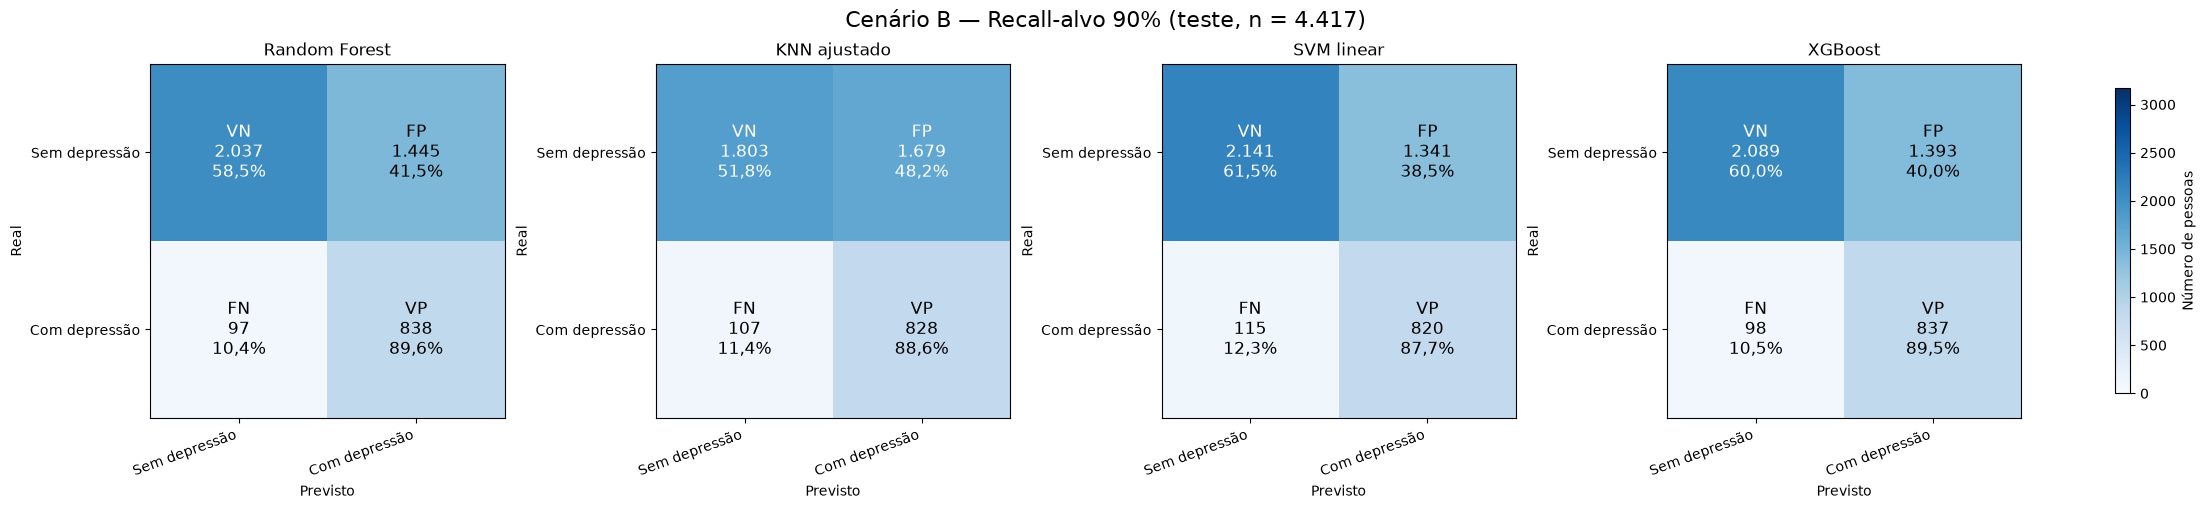

In [2]:
plotar_matrizes('Recall-alvo 90%', 'conclusao_matrizes_confusao_recall_alvo_90.png')

### Como interpretar

- A diagonal (VN e VP) contém os acertos; fora dela estão os falsos positivos e os casos de depressão não identificados (FN).
- Compare cada modelo entre os dois gráficos: reduzir o limiar para buscar recall alto tende a diminuir FN e aumentar FP. Os dois pontos usam os mesmos registros.
- Compare horizontalmente os modelos no mesmo ponto de operação. Os limiares padrão são diferentes entre algoritmos; o segundo gráfico permite comparar o custo de buscar o mesmo recall-alvo no treino.

## O que aprendemos sobre a hipótese

A retirada das variáveis de ansiedade piorou o desempenho, como esperado, mas **não eliminou a capacidade preditiva**. No cenário B, todos os modelos ficaram bem acima da referência de acaso (ROC-AUC de 0,50). Isso sustenta a hipótese de que informações não diretamente relacionadas a sintomas de saúde mental carregam sinal útil para prever depressão.

| Modelo no cenário B | ROC-AUC | ROC-AUC sem cognição e sem solidão |
|---|---:|---:|
| SVM linear ajustado | 0,856 | 0,813 |
| XGBoost ajustado | 0,856 | 0,811 |
| Random Forest | 0,841 | 0,804 |
| KNN ajustado | 0,816 | 0,778 |

No cenário A, SVM, XGBoost e Random Forest alcançaram ROC-AUC de aproximadamente 0,915; o KNN original ficou em 0,833. A queda ao retirar ansiedade foi, portanto, esperada e relevante, mas os modelos ainda mantiveram discriminação substancial no cenário B.

Os sinais observados incluem idade, autoavaliação de saúde, dor crônica, limitações funcionais, suporte social e condições socioeconômicas. Cognição e solidão também aparecem como preditores importantes. Ao removê-las, o desempenho diminui, mas continua acima do acaso, o que mostra que o resultado não depende exclusivamente dessas variáveis.

**Interpretação cuidadosa:** o cenário B demonstra que variáveis sem sintomas diretos de depressão/ansiedade podem ajudar a prever depressão. Ele **não prova que doenças físicas, isoladamente, sejam suficientes**, porque os modelos também usam idade, cognição, funcionamento, relações sociais e outras características. Para testar especificamente a hipótese de doenças físicas, seria necessário comparar um cenário restrito a variáveis físicas com cenários sociais e funcionais separados.

## Comparação dos algoritmos e aprendizado sobre recall

O SVM linear e o XGBoost tiveram o maior ROC-AUC no cenário B (0,856), seguidos por Random Forest (0,841) e KNN ajustado (0,816), em um único split. A proximidade entre um modelo linear e um mais flexível sugere que maior complexidade não trouxe uma vantagem clara neste conjunto de variáveis. Isso não demonstra que o sinal seja exclusivamente linear; a confirmação exigiria validações repetidas e externas.

Em saúde, deixar de identificar um caso pode ser mais custoso do que encaminhar alguém sem depressão para uma avaliação adicional. Por isso, também foram testados pontos de operação com recall elevado. A tabela mostra o resultado no teste ao selecionar no treino um limiar para recall-alvo de 90%:

| Modelo | Recall obtido | Precisão ponderada | Falsos positivos (contagem) | Amostra sinalizada |
|---|---:|---:|---:|---:|
| SVM linear | 86,9% | 38,5% | 1.341 | 48,9% |
| XGBoost | 88,4% | 38,8% | 1.393 | 50,5% |
| Random Forest | 88,3% | 38,0% | 1.445 | 51,7% |
| KNN ajustado | 87,2% | 34,0% | 1.679 | 56,8% |

O recall maior tem um custo: aproximadamente metade da amostra é sinalizada e há muitos falsos positivos. A precisão fica entre 34% e 39%, embora seja superior à prevalência do desfecho (cerca de 21%). O limiar não é uma escolha puramente estatística: deve refletir a capacidade de acompanhamento, o custo de falsos positivos e o risco de casos perdidos. Os resultados também mostram que o recall medido no teste ficou alguns pontos abaixo do alvo de 90%, pois o limiar foi selecionado sem consultar o teste.

As tentativas de aumentar o peso da classe positiva no Random Forest, SVM e XGBoost elevaram o recall no limiar padrão, mas não melhoraram de forma clara a curva de precisão-recall: elas principalmente mudaram o ponto de operação, aumentando falsos positivos.

## Limitações e próximos passos

- A avaliação final usa um único split de treino e teste. Pequenas diferenças entre modelos podem resultar da variação da amostra; repetir a validação ou usar validação cruzada externa daria estimativas mais estáveis.
- A análise inclui somente registros completos (22.084 de 24.215), o que pode limitar a representatividade se a ausência de respostas não for aleatória.
- Cognição e solidão podem se sobrepor a manifestações ou consequências da depressão. Sua exclusão é uma análise de sensibilidade, não uma prova de que todo o sinal restante venha de doenças físicas.
- As métricas agregadas não demonstram desempenho equivalente entre grupos demográficos. Uma aplicação futura deve avaliar calibração, taxas de erro por subgrupo e validade em outra amostra e período.
- Um sistema de rastreio exigiria validação externa, revisão clínica e definição explícita do limiar em função dos recursos e consequências de cada tipo de erro. Os modelos deste estudo não devem ser interpretados como diagnóstico.
- Os resultados indicam **associação preditiva**, não causalidade: não demonstram que dor, doença física ou qualquer outra variável cause depressão.

## Conclusão

No NHIS 2025 analisado, informações sem sintomas diretos de depressão e ansiedade conservaram capacidade preditiva relevante, inclusive após retirar cognição e solidão. Isso apoia a hipótese de que características físicas, funcionais e sociais podem contribuir para identificar pessoas com depressão e justifica investigar mais profundamente o papel de dor crônica, limitações funcionais e autoavaliação de saúde.

Nenhum algoritmo foi claramente superior em todos os critérios. SVM e XGBoost tiveram o melhor ROC-AUC; o Random Forest ficou próximo; e o KNN melhorou de forma mais evidente após ponderação das variáveis. Para priorizar a identificação de casos, o ajuste do limiar foi mais importante que trocar de algoritmo, mas o ganho de recall veio acompanhado de muitos falsos positivos. Assim, os achados são promissores como evidência de viabilidade preditiva e ponto de partida para um estudo mais específico — não como prova de que dados exclusivamente físicos bastam, nem como ferramenta clínica pronta para uso.